# k-means from scratch

This notebook rebuilds what the library lab [`kmeans_lab.ipynb`](kmeans_lab.ipynb) uses, with nothing but NumPy, and checks each
result against scikit-learn or SciPy on the same data. The theory is in [k-means README](README.md).

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers), then run top to bottom (**Run All**). Later cells reuse functions
   from earlier ones.
2. Each lab has the same shape: the algorithm in plain steps (markdown) → the code, commented line by line →
   a **comparison with the library** → a "How to read this" box.
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself, demonstrated on a
   small case and then fixed.
4. scikit-learn and SciPy are imported **only to check** our answers. No internet needed.

Labs are numbered like the library lab: **Lab N here rebuilds what library Lab N runs**, and each one links to
its twin, so you can put the library's result and our version of it side by side. Lab 4 (where k-means fails) has no
from-scratch part: the failures come from the inertia objective, not from the code, so there is nothing new to build.

| Lab | Algorithm | Checked against | Library twin |
|---|---|---|---|
| [1](#lab-1) | Lloyd's algorithm | `sklearn.cluster.KMeans` | [Lab 1](kmeans_lab.ipynb#lab-1) |
| [2](#lab-2) | k-means++ starts, and [an exact toy with 3 pairs](#toy) | `KMeans`; exact enumeration; `KMeans` from all 20 starts | [Lab 2](kmeans_lab.ipynb#lab-2) |
| [3](#lab-3) | silhouette and the elbow, and [what each costs as n grows](#lab-3-cost) | `sklearn.metrics.silhouette_score` | [Lab 3](kmeans_lab.ipynb#lab-3) |
| [4b](#lab-4b) | mini-batch k-means, and [why its step size must shrink](#lab-4b-step) | `MiniBatchKMeans`; our Lloyd from Lab 1 | [Lab 4b](kmeans_lab.ipynb#lab-4b) |
| [Summary](#summary) | what matched, and the hurdles | | |

**Distance helper** (defined in the first code cell): `pairwise_distances(A, B)` uses
$\lVert a - b \rVert^2 = \lVert a \rVert^2 - 2\,a \cdot b + \lVert b \rVert^2$: fast and memory-light, for points-to-centroids distances.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

# scikit-learn / SciPy are imported ONLY to check our answers against theirs; every algorithm below is plain NumPy.
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def pairwise_distances(A, B):
    """Euclidean distance between every row of A (n x d) and every row of B (m x d) -> an n x m matrix.

    Uses ||a - b||² = ||a||² - 2 a·b + ||b||², which needs only an n x m matrix in memory, instead of the
    n x m x d array that `A[:, None, :] - B[None, :, :]` would build (see the memory hurdle below)."""
    squared = (A ** 2).sum(axis=1)[:, None] - 2 * A @ B.T + (B ** 2).sum(axis=1)[None, :]
    return np.sqrt(np.maximum(squared, 0))          # rounding can make a true 0 come out as -1e-15; clip it to 0


def plot_clusters(ax, X, labels, title):
    """Scatter 2-D points coloured by cluster label; label -1 (noise) as grey crosses."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")

<a id="lab-1"></a>

## Lab 1 · k-means, one iteration at a time

*Library twin:* [Lab 1 in `kmeans_lab.ipynb`](kmeans_lab.ipynb#lab-1) runs scikit-learn's k-means from a random start and draws each centroid's path.

**[README §1–2](README.md#1-inertia-within-cluster-sum-of-squares-wcss).** k-means looks for k centroids that minimise the **inertia** (within-cluster sum of squares):

$$\text{inertia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2, \qquad c(i) = \text{the cluster of point } i$$

**Lloyd's algorithm** alternates two steps, each of which can only lower the inertia:

1. **Assign:** give every point to its nearest centroid. (For fixed centroids this is the best possible assignment.)
2. **Update:** move every centroid to the mean of its points. (For a fixed assignment the mean is the point with the
   smallest sum of squared distances to the group.)

Repeat until no centroid moves. The code below splits this into `assign`, `update` and the loop `kmeans`, and adds
`kmeans_plus_plus` for the starting centroids. The check uses the same data and the same 4 starting centroids for
both our code and scikit-learn (`init=start`, `tol=0` so it also runs until nothing moves).

ours        : inertia 1718.496012, iterations 3
scikit-learn: inertia 1718.496012, iterations 3
same labels: True | largest centroid difference: 3.552713678800501e-15
inertia never went up: True


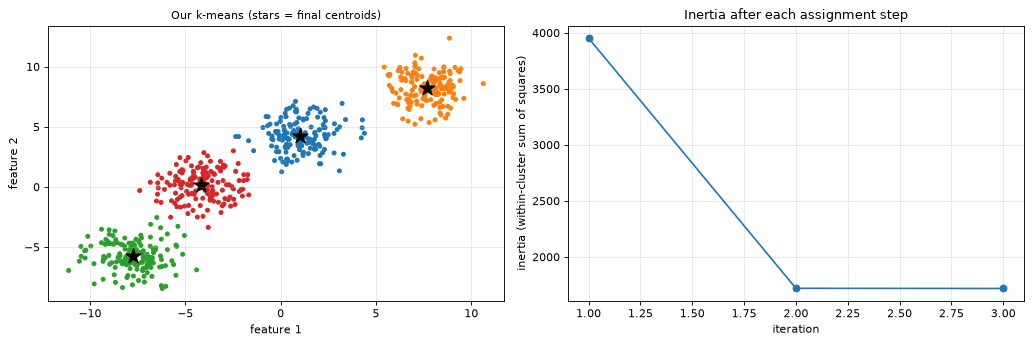

In [2]:
def assign(X, centroids):
    """Step 1 of k-means: the index of the nearest centroid for every point, and that squared distance."""
    distances = pairwise_distances(X, centroids)          # n x k: distance from every point to every centroid
    labels = distances.argmin(axis=1)                      # nearest centroid; ties go to the lower index (like sklearn)
    return labels, distances[np.arange(len(X)), labels] ** 2


def update(X, labels, centroids):
    """Step 2 of k-means: move each centroid to the mean of its points.

    A centroid that lost all its points would get the mean of nothing (NaN). Instead it is moved onto the point that
    is currently worst served (farthest from its own centroid), which is also what scikit-learn does."""
    new = centroids.copy()
    _, squared = assign(X, centroids)
    for k in range(len(centroids)):
        members = X[labels == k]
        if len(members):
            new[k] = members.mean(axis=0)                  # the mean minimises the sum of squared distances
        else:
            worst = squared.argmax()                       # the point paying the most inertia right now
            new[k] = X[worst]
            squared[worst] = 0                             # don't give the same point to two empty clusters
    return new


def kmeans(X, initial_centroids, max_iter=300):
    """Lloyd's algorithm: alternate assign / update until no centroid moves.
    Returns (labels, centroids, inertia after every iteration)."""
    centroids = np.asarray(initial_centroids, dtype=float)
    history = []
    for _ in range(max_iter):
        labels, squared = assign(X, centroids)
        history.append(squared.sum())                      # inertia of the current assignment
        new_centroids = update(X, labels, centroids)
        if np.array_equal(new_centroids, centroids):       # nothing moved: the next assignment would be identical
            break
        centroids = new_centroids
    labels, squared = assign(X, centroids)                 # final assignment to the final centroids
    return labels, centroids, history


def kmeans_plus_plus(X, k, rng):
    """k-means++ starting centroids: the first is a random point; each next one is a random point drawn with
    probability proportional to its SQUARED distance to the nearest centroid chosen so far ("D² sampling")."""
    centroids = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        nearest_sq = pairwise_distances(X, np.array(centroids)).min(axis=1) ** 2   # D(x)² for every point
        centroids.append(X[rng.choice(len(X), p=nearest_sq / nearest_sq.sum())])
    return np.array(centroids)


# Check against scikit-learn: same data, same starting centroids, Lloyd's algorithm, run to full convergence
X_km, _ = make_blobs(600, centers=4, cluster_std=1.2, random_state=3)
start = X_km[np.random.default_rng(11).choice(len(X_km), 4, replace=False)]          # 4 random data points
labels, centroids, history = kmeans(X_km, start)
reference = KMeans(4, init=start, n_init=1, algorithm="lloyd", tol=0).fit(X_km)       # tol=0: stop only when stable

print(f"ours        : inertia {history[-1]:.6f}, iterations {len(history)}")
print(f"scikit-learn: inertia {reference.inertia_:.6f}, iterations {reference.n_iter_}")
print("same labels:", np.array_equal(labels, reference.labels_),
      "| largest centroid difference:", np.abs(centroids - reference.cluster_centers_).max())
print("inertia never went up:", bool(np.all(np.diff(history) <= 1e-9)))
assert np.array_equal(labels, reference.labels_) and np.isclose(history[-1], reference.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_clusters(axes[0], X_km, labels, "Our k-means (stars = final centroids)")
axes[0].scatter(*centroids.T, c="black", marker="*", s=200)
axes[1].plot(range(1, len(history) + 1), history, marker="o")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("inertia (within-cluster sum of squares)")
axes[1].set_title("Inertia after each assignment step")
plt.tight_layout(); plt.show()

> **How to read this**
> * Same starting centroids, same answer: inertia **1718.496012** for both, **3** iterations for both, identical
>   labels, and centroids equal to about 1e-15 (rounding). The `assert` stops the notebook if that ever changes.
> * The inertia never goes up, as the two-step argument above says (right plot). This start happened to be a good one
>   (3 iterations); library Lab 1 shows a random start that needs 15.

> **Implementation hurdle — an empty cluster.** If a starting centroid is far from every point (or loses all its
> points during the run), the update step takes the mean of **zero** points. NumPy returns NaN, and every distance to
> a NaN centroid is NaN from then on. Our `update` instead moves an empty centroid onto the point that is currently
> worst served (largest squared distance to its own centroid), which is also what scikit-learn does.

In [3]:
# A starting centroid far from every point never wins a single point in the first assignment
X_tiny = np.array([[0.0, 0.0], [0.0, 1.0], [10.0, 0.0], [10.0, 1.0]])
bad_start = np.array([[0.0, 0.5], [10.0, 0.5], [100.0, 100.0]])      # the third centroid is miles away

labels_tiny, _ = assign(X_tiny, bad_start)
print("first assignment:", labels_tiny, "-> cluster 2 has", np.sum(labels_tiny == 2), "points")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)                   # numpy warns "mean of empty slice"
    naive = np.array([X_tiny[labels_tiny == k].mean(axis=0) for k in range(3)])  # mean of an empty array
print("naive update, centroid 2:", naive[2], " <- NaN poisons every later distance")
labels_fixed, centroids_fixed, _ = kmeans(X_tiny, bad_start)
print("our update   : final centroids", centroids_fixed.tolist(), "labels", labels_fixed)

first assignment: [0 0 1 1] -> cluster 2 has 0 points
naive update, centroid 2: [nan nan]  <- NaN poisons every later distance
our update   : final centroids [[0.0, 1.0], [10.0, 0.5], [0.0, 0.0]] labels [2 0 1 1]


> **How to read this**
> * Four points in two pairs; the third starting centroid sits at (100, 100), so the first assignment gives it
>   **0** points (`[0 0 1 1]`).
> * The naive update makes that centroid **[nan nan]**.
> * Ours moves it onto (0, 0), one of the two worst-served points (it picks the first of the tie), and the run ends
>   with three real clusters: the left pair split in two, the right pair together.

> **Implementation hurdle — memory.** The obvious way to get every point-to-centroid distance,
> `X[:, None, :] - C[None, :, :]`, builds an n × k × d array before summing over d. With 20,000 points, 100
> centroids and 50 features that array is 100 million numbers. The expansion
> $\lVert x \rVert^2 - 2\,x \cdot c + \lVert c \rVert^2$ needs only the n × k result, and the middle term is one matrix
> product, which NumPy computes very fast.

In [4]:
X_big = np.random.default_rng(SEED).normal(size=(20_000, 50))       # 20,000 points with 50 features
C_big = X_big[:100]                                                 # 100 centroids

broadcast_bytes = X_big.shape[0] * C_big.shape[0] * X_big.shape[1] * 8   # n x k x d float64 array
matrix_bytes = X_big.shape[0] * C_big.shape[0] * 8                       # n x k float64 matrix
start_time = time.perf_counter(); fast = pairwise_distances(X_big, C_big); t_fast = time.perf_counter() - start_time
start_time = time.perf_counter()
slow = np.sqrt(((X_big[:, None, :] - C_big[None, :, :]) ** 2).sum(axis=2))   # the "obvious" broadcasting version
t_slow = time.perf_counter() - start_time
print(f"broadcasting builds a {broadcast_bytes / 1e6:.0f} MB array, the expansion trick a {matrix_bytes / 1e6:.0f} MB one")
print(f"time: broadcasting {t_slow:.2f} s, expansion trick {t_fast:.3f} s; largest difference {np.abs(fast - slow).max():.1e}")

broadcasting builds a 800 MB array, the expansion trick a 16 MB one
time: broadcasting 0.15 s, expansion trick 0.007 s; largest difference 2.4e-07


> **How to read this**
> * Broadcasting builds an **800 MB** temporary array; the expansion trick only the **16 MB** answer.
> * It is also much faster (see the printed times; yours will differ). The results agree to about **2e-7**. That
>   small rounding error is harmless for k-means, but the [hierarchical from-scratch notebook](../02-hierarchical/hierarchical_from_scratch.ipynb#lab-5) shows where it isn't.

<a id="lab-2"></a>

## Lab 2 · Why the starting centroids matter: random vs k-means++

*Library twin:* [Lab 2 in `kmeans_lab.ipynb`](kmeans_lab.ipynb#lab-2) compares 100 random and 100 k-means++ starts with scikit-learn.

### k-means++ starting centroids

**[README §5](README.md#5-the-start-matters-k-means).** Pick the first centroid: a data point chosen uniformly at random. Then, repeatedly, pick a data point at random with probability
proportional to $D(x)^2$, the squared distance from $x$ to the nearest centroid chosen so far. Points far from every
existing centroid are likely picks, so the starts spread over the data. Below: 100 runs of **our** k-means from random
starts and 100 from our k-means++ starts, on the 10 blobs of library [Lab 2](kmeans_lab.ipynb#lab-2).

random    : median inertia  1667.3, worst  9946.2, within 1 % of the best: 3%
k-means++ : median inertia   715.8, worst  2741.1, within 1 % of the best: 29%


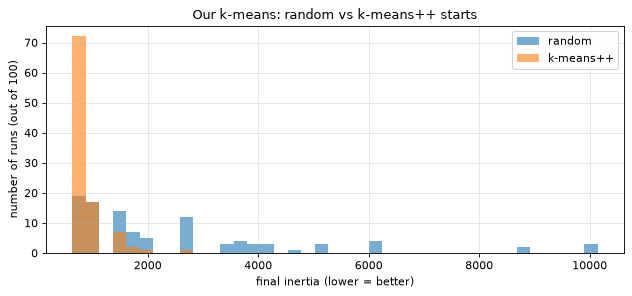

In [5]:
# 100 runs from random starts vs 100 runs from k-means++ starts, using OUR k-means, on 10 blobs (as in library Lab 2)
X_pp, _ = make_blobs(1000, centers=10, cluster_std=0.6, center_box=(-12, 12), random_state=42)
finals = {"random": [], "k-means++": []}
for seed in range(100):
    rng = np.random.default_rng(seed)
    finals["random"].append(kmeans(X_pp, X_pp[rng.choice(len(X_pp), 10, replace=False)])[2][-1])
    finals["k-means++"].append(kmeans(X_pp, kmeans_plus_plus(X_pp, 10, np.random.default_rng(seed)))[2][-1])
best = min(min(v) for v in finals.values())
for name, values in finals.items():
    values = np.array(values)
    print(f"{name:10s}: median inertia {np.median(values):7.1f}, worst {values.max():7.1f}, "
          f"within 1 % of the best: {np.mean(values <= best * 1.01):.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(best * 0.98, max(max(v) for v in finals.values()) * 1.02, 40)
for name, values in finals.items():
    ax.hist(values, bins=bins, alpha=0.6, label=name)
ax.set_xlabel("final inertia (lower = better)"); ax.set_ylabel("number of runs (out of 100)")
ax.set_title("Our k-means: random vs k-means++ starts"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * **Random starts:** median inertia **1667.3**, worst **9946.2**, only **3 %** of runs within 1 % of the best.
> * **Our k-means++:** median **715.8**, worst **2741.1**, **29 %** of runs within 1 % of the best. Far better.
> * scikit-learn's k-means++ reached the best in 50 % of runs in library [Lab 2](kmeans_lab.ipynb#lab-2). It uses the **greedy** variant: at each
>   step it draws $2 + \ln k$ candidates and keeps the one that lowers the inertia most. Same idea, a little more work,
>   fewer bad starts.

<a id="toy"></a>

### Why the start matters: an exact toy (3 pairs)

The histogram above shows *that* random starts end worse. This toy is small enough to show *why*, exactly: every
possible start can be listed, run, and given its probability.

**Setup.** Six points on a line in three pairs X, Y, Z; inside each pair the two points are **s** apart. **Y's left
point is the origin**, and both gaps are measured **edge to edge**, between the facing points:

* Y = {0, s}
* Z = {s + Δ, 2s + Δ}: **Δ** is the gap from Y's right point to Z's left point;
* X = {−D − s, −D}: **D** is the gap from X's right point to the origin. X is far away: **D = 4Δ**.

So the pair centres are $-D - \tfrac{s}{2}$, $\tfrac{s}{2}$ and $\tfrac{3s}{2} + \Delta$: centre to centre, X–Y is
$D + s$ and Y–Z is $\Delta + s$. Write $r = \Delta / s$ (the Y–Z gap measured in pair widths); every formula below
depends on the gap only through $1 + r = (\Delta + s)/s$, the Y–Z centre distance in pair widths. The code uses
$s = 1$, $\Delta = 10$, $D = 40$, so $r = 10$ and the points are −41, −40, 0, 1, 11, 12. The gaps are unequal on
purpose: with equal gaps Y would sit exactly halfway between X and Z, and the result would depend on how ties are
broken.

```mermaid
flowchart LR
    subgraph line["3 pairs, each s wide"]
        direction LR
        X["X: −D−s … −D"] -- "D" --- Y["Y: 0 … s"] -- "Δ" --- Z["Z: s+Δ … 2s+Δ"]
    end
    subgraph opt["Optimum · inertia = 3s²/2"]
        direction LR
        O1(("c₁ = −D − s/2")) ~~~ O2(("c₂ = s/2")) ~~~ O3(("c₃ = 3s/2 + Δ"))
    end
    subgraph stuck["Stuck · inertia = s² + (Δ+s)²"]
        direction LR
        S1(("c₁ = −D − s")) ~~~ S2(("c₂ = −D")) ~~~ S3(("c₃ = s + Δ/2 for Y and Z"))
    end
    line --> A["1 in each pair · 8 starts"]
    line --> B["2 in Y + 1 in X · 2 starts"]
    line --> C["2 in Y + 1 in Z · 2 starts"]
    line --> E["2 in Z + 1 in X · 2 starts"]
    line --> F["2 in Z + 1 in Y · 2 starts"]
    line --> G["2 in X + 1 in Y or Z · 4 starts"]
    A -- "nothing to fix" --> opt
    B & C & E -- "one repair" --> opt
    F -- "two repairs" --> opt
    G -- "no way out" --> stuck
```

(The diagram renders in JupyterLab ≥ 4.1 and VS Code; GitHub may show it as text. The first code cell below draws the
same picture with matplotlib.)

**Every possible start.** Three starting centroids are three of the six points: $\binom{6}{3} = 20$ starts. Either
each pair gets one (2·2·2 = 8 starts), or one pair gets two, another gets one and the third gets **none** (12
starts; a pair has only 2 points, so three in one pair is impossible). The first assignment decides everything: the
uncovered pair must join some centroid.

| Two centroids in… | Starts | What Lloyd's does (s = 1, Δ = 10, D = 40) | Ending | Iterations |
|---|---|---|---|---|
| (one in each pair) | 8 | nothing to fix: each centroid moves to its pair's centre | optimum, 1.5 | 2 |
| Y, one in X | 2 | uncovered Z joins Y's right centroid and drags it to 8; Y's right point is now nearer Y's left centroid and moves back | optimum, 1.5 | 3 |
| Y, one in Z | 2 | uncovered X joins Y's left centroid and drags it to −27; Y's left point moves back to Y's right centroid | optimum, 1.5 | 3 |
| Z, one in X | 2 | uncovered Y joins Z's left centroid and drags it to 4; Z's left point moves back to Z's right centroid | optimum, 1.5 | 3 |
| Z, one in Y | 2 | uncovered X joins Y's centroid, which lands between X and Y at −20; both Y points are now nearer Z's left centroid and defect to it (→ 4); then Z's left point moves back | optimum, 1.5 | 4 |
| X, one in Y or Z | 4 | uncovered Z (or Y) joins the single Y (or Z) centroid, which settles at 6, between Y and Z; X's two centroids are 40 away, so nothing ever moves again | **stuck, 122.0** | 2 |

So 8 bad starts are **repaired** and only 4 get **stuck**. Two rows begin the same way, with the uncovered pair merging
into a single centroid's cluster, yet end differently:

* **2 in Z, one in Y:** X and Y merge, and their shared centroid lands halfway between them, about 20 from Y's points.
  Z's spare centroid is only about 10 away, so Y's points leave and the merge breaks up.
* **2 in X:** Y and Z merge, and their shared centroid lands about 5 from each of their points. X's spare centroid is
  40 or more away, so no point ever leaves.

A merge is permanent only when the two merged pairs are each other's nearest neighbours and the doubled pair is far
away. Here that happens only when the doubled pair is the isolated pair X.

**The two endings, as equations.** A pair split between two centroids costs 0 (each point is its own centroid). A
pair under one centroid costs $2\,(s/2)^2 = s^2/2$.

$$\text{optimum (one centroid per pair)} = 3 \cdot \frac{s^2}{2} = \frac{3s^2}{2}$$

In the stuck ending X is split and one centroid serves Y ∪ Z. That centroid is the mean of 0, s, s + Δ, 2s + Δ, i.e.
$s + \Delta/2$, halfway between the two pair centres, which are $\Delta + s$ apart. Each of the four points is
$\frac{\Delta + s}{2} \pm \frac{s}{2}$ from it:

$$\text{stuck} = 0 + 2\left[\left(\tfrac{\Delta + s}{2} + \tfrac{s}{2}\right)^2 + \left(\tfrac{\Delta + s}{2} - \tfrac{s}{2}\right)^2\right] = s^2 + (\Delta + s)^2 = s^2\left[1 + (1 + r)^2\right]$$

So the stuck ending is $\frac{s^2 + (\Delta + s)^2}{3s^2/2} = \frac{2}{3}\left[1 + (1 + r)^2\right]$ times the optimum:
**81×** at $r = 10$, and it grows without limit as the pairs move apart.

<details>
<summary><b>Why Lloyd's cannot leave the stuck state</b> (click to expand)</summary>

Lloyd's stops when (1) every point is nearest its own centroid and (2) every centroid is the mean of its points.

* (2) holds by construction: each X point is its own centroid, and $c_3 = s + \Delta/2$ is the mean of Y ∪ Z.
* (1): the X points are at distance 0 from their centroids. The Y ∪ Z points farthest from $c_3$ are the outer ones,
  0 and $2s + \Delta$, both $s + \Delta/2$ away. The X centroid nearest to Y is X's right point at $-D$, which is $D$
  from the origin. So nothing moves as long as $s + \Delta/2 < D$; with $D = 4\Delta$ that is $\Delta > 2s/7$ —
  always, for real pairs.

Moving c₂ from X over to Y would lower the inertia a lot, but no single assign or update step makes that jump: Lloyd's
only ever moves a centroid to the mean of the points nearest to it.
</details>

points (x only): [-41. -40.   0.   1.  11.  12.]
good start -> centroids [-40.5   0.5  11.5], inertia 1.5   (formula 3s²/2 = 1.5)
bad start  -> centroids [-41. -40.   6.], inertia 122.0 (formula s² + (Δ + s)² = 122.0)


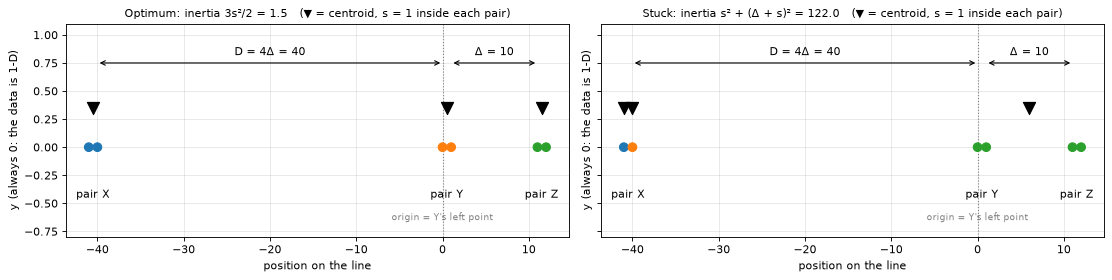

In [6]:
from itertools import combinations


def three_pairs(r, s=1.0):
    """The 6-point toy: pairs X, Y, Z on a line (stored as 2-D points with y = 0 so every helper above works).
    Y's left point is the origin. Δ = r·s is the EDGE-TO-EDGE gap from Y's right point to Z's left point, and
    D = 4Δ the edge-to-edge gap from X's right point to the origin. Returns (points, pair index 0/1/2)."""
    gap, far = r * s, 4 * r * s                                       # Δ and D
    x = np.array([-far - s, -far,                                     # X = {-D - s, -D}
                  0.0, s,                                             # Y = {0, s}: the origin is Y's left point
                  s + gap, 2 * s + gap])                              # Z = {s + Δ, 2s + Δ}
    return np.column_stack([x, np.zeros(6)]), np.repeat([0, 1, 2], 2)


r, s = 10.0, 1.0                                                     # Δ = r·s = 10, D = 4Δ = 40
X_toy, pair = three_pairs(r, s)
gap, far = r * s, 4 * r * s
opt_formula, stuck_formula = 3 * s**2 / 2, s**2 + (gap + s)**2       # the two equations above

# Run OUR kmeans from one good start (one point per pair) and one bad start (both X points + one Y point)
good_labels, good_c, good_hist = kmeans(X_toy, X_toy[[0, 2, 4]])
bad_labels, bad_c, bad_hist = kmeans(X_toy, X_toy[[0, 1, 2]])
print(f"points (x only): {X_toy[:, 0]}")
print(f"good start -> centroids {good_c[:, 0]}, inertia {good_hist[-1]:.1f}   (formula 3s²/2 = {opt_formula:.1f})")
print(f"bad start  -> centroids {bad_c[:, 0]}, inertia {bad_hist[-1]:.1f} (formula s² + (Δ + s)² = {stuck_formula:.1f})")
assert np.isclose(good_hist[-1], opt_formula) and np.isclose(bad_hist[-1], stuck_formula)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, labels, cents, title in [(axes[0], good_labels, good_c, f"Optimum: inertia 3s²/2 = {opt_formula:.1f}"),
                                 (axes[1], bad_labels, bad_c, f"Stuck: inertia s² + (Δ + s)² = {stuck_formula:.1f}")]:
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=labels, cmap="tab10", vmin=0, vmax=9, s=60, zorder=3)   # colour = cluster
    ax.scatter(cents[:, 0], cents[:, 1] + 0.35, c="black", marker="v", s=120, zorder=3)            # centroid markers
    for name, centre in zip("XYZ", [-far - s / 2, s / 2, 1.5 * s + gap]):
        ax.text(centre, -0.45, f"pair {name}", ha="center", fontsize=10)                          # pair names
    ax.axvline(0, color="gray", ls=":", lw=1)                                                     # the origin
    ax.text(0, -0.65, "origin = Y's left point", ha="center", fontsize=8, color="gray")
    ax.annotate("", xy=(-far, 0.75), xytext=(0, 0.75), arrowprops=dict(arrowstyle="<->"))        # D: X's right to 0
    ax.text(-far / 2, 0.82, f"D = 4Δ = {far:.0f}", ha="center")
    ax.annotate("", xy=(s, 0.75), xytext=(s + gap, 0.75), arrowprops=dict(arrowstyle="<->"))     # Δ: Y's right to Z's left
    ax.text(s + gap / 2, 0.82, f"Δ = {gap:.0f}", ha="center")
    ax.set_ylim(-0.8, 1.1); ax.set_title(title + "   (▼ = centroid, s = 1 inside each pair)", fontsize=10)
    ax.set_xlabel("position on the line"); ax.set_ylabel("y (always 0: the data is 1-D)")
plt.tight_layout(); plt.show()

> **How to read this**
> * The points are **−41, −40, 0, 1, 11, 12**: the origin is Y's left point, D = 40 and Δ = 10 are edge-to-edge gaps.
> * Our `kmeans` from the start (one point per pair) ends with centroids at **−40.5, 0.5, 11.5** (the pair centres)
>   and inertia **1.5** = 3s²/2.
> * From the start (both X points + one Y point) it ends with centroids at **−41, −40, 6** and inertia
>   **122.0** = s² + (Δ + s)² = 1 + 121. Both match the equations (the `assert` checks). Same data, same algorithm:
>   only the start differs.
> * In the right plot Y and Z share one colour (one cluster) while X's two points are split, as in the diagram.

#### All 20 random starts

scikit-learn's `init="random"` picks 3 distinct data points, all equally likely, so each of the 20 starts in the
table above has probability 1/20. Below, **every** start is run through our `kmeans` and checked against
scikit-learn's `KMeans` with the same start. Iterations are counted like scikit-learn's `n_iter_`, including the last
pass that confirms nothing moves, so **2** is the minimum here.

<details>
<summary><b>The table's traces in symbols: when each start recovers</b> (click to expand)</summary>

Points: X = {−D − s, −D}, Y = {0, s}, Z = {s + Δ, 2s + Δ}, with D = 4Δ.

* **2 in X, 1 in Y (or Z) → stuck.** Y and Z all go to the single centroid, which becomes
  mean(Y ∪ Z) = $s + \Delta/2$ (= 6). The farthest of those points is $s + \Delta/2$ away from it, while X's nearest
  centroid is at least $D$ away, so nothing moves while $s + \Delta/2 < D$. Final inertia $s^2 + (\Delta + s)^2$.
* **2 in Y, 1 in X → recovers.** Z goes to the centroid at s, which moves to
  $\frac{s + (s + \Delta) + (2s + \Delta)}{3} = \frac{4s + 2\Delta}{3}$ (= 8). The point s is now $s$ from the centroid
  at 0 but $\frac{s + 2\Delta}{3}$ from the dragged one, so it moves back whenever $\Delta > s$.
* **2 in Y, 1 in Z → recovers.** X goes to the centroid at 0, which moves to $\frac{-2D - s}{3}$ (= −27). The point 0
  is now $s$ from the centroid at s and $\frac{2D + s}{3}$ from the dragged one, so it moves back.
* **2 in Z, 1 in X → recovers.** Y goes to the centroid at s + Δ, which moves to $\frac{2s + \Delta}{3}$ (= 4). The
  point s + Δ is now $s$ from the centroid at 2s + Δ and $\frac{2\Delta + s}{3}$ from the dragged one, so it moves
  back whenever $\Delta > s$.
* **2 in Z, 1 in Y → recovers, but needs two repairs.** X goes to Y's centroid (D away, against D + s + Δ to Z's).
  That centroid becomes mean(X ∪ Y) = $-D/2$ (= −20), leaving Y's points $D/2$ and $D/2 + s$ from it but only
  $s + \Delta$ and Δ from Z's left centroid. Both Y points defect when $s + \Delta < D/2$, i.e. $\Delta > s$ when
  $D = 4\Delta$. Z's left centroid then becomes $\frac{2s + \Delta}{3}$ (= 4), as in the row above, and Z's left
  point moves back. With other gaps, e.g. $D = \Delta$, the defection never happens and this start gets stuck too.
</details>

In [7]:
def start_class(start, pair):
    """Name a start by which pairs its 3 points come from: 'one per pair' or e.g. '2 in X, 1 in Y'."""
    picked = list(pair[list(start)])
    if len(set(picked)) == 3:
        return "one per pair"
    doubled = max(set(picked), key=picked.count)                     # the pair that got two starting centroids
    single = [p for p in picked if p != doubled][0]
    return f"2 in {'XYZ'[doubled]}, 1 in {'XYZ'[single]}"


def run_all_starts(X, pair):
    """Run OUR kmeans from every one of the C(6,3) = 20 possible 3-point starts.
    Returns {frozenset(start indices): (class name, final inertia, iterations)}."""
    results = {}
    for start in combinations(range(len(X)), 3):
        _, _, history = kmeans(X, X[list(start)])
        results[frozenset(start)] = (start_class(start, pair), history[-1], len(history))
    return results


runs = run_all_starts(X_toy, pair)

# Check every start against scikit-learn (same start, Lloyd, tol=0)
for start, (_, inertia, _) in runs.items():
    ref = KMeans(3, init=X_toy[sorted(start)], n_init=1, algorithm="lloyd", tol=0).fit(X_toy)
    assert np.isclose(inertia, ref.inertia_)

print(f"{'start class':16s} {'count':>5s} {'final inertia':>14s} {'iterations':>11s}")
for name in sorted({c for c, _, _ in runs.values()}, key=lambda c: (c != "one per pair", c)):
    group = [(inr, it) for c, inr, it in runs.values() if c == name]
    print(f"{name:16s} {len(group):5d} {group[0][0]:14.1f} {group[0][1]:11d}")
inertias = np.array([inr for _, inr, _ in runs.values()])
iterations = np.array([it for _, _, it in runs.values()])
print(f"\nrandom init (each of the 20 starts has probability 1/20):")
print(f"  P(optimum) = {np.mean(np.isclose(inertias, opt_formula)):.2f}, "
      f"E[inertia] = {inertias.mean():.2f} (formula s²(7 + (1 + r)²)/5 = {s**2 * (7 + (1 + r)**2) / 5:.2f}), "
      f"E[iterations] = {iterations.mean():.2f}")

start class      count  final inertia  iterations
one per pair         8            1.5           2
2 in X, 1 in Y       2          122.0           2
2 in X, 1 in Z       2          122.0           2
2 in Y, 1 in X       2            1.5           3
2 in Y, 1 in Z       2            1.5           3
2 in Z, 1 in X       2            1.5           3
2 in Z, 1 in Y       2            1.5           4

random init (each of the 20 starts has probability 1/20):
  P(optimum) = 0.80, E[inertia] = 25.60 (formula s²(7 + (1 + r)²)/5 = 25.60), E[iterations] = 2.50


> **How to read this**
> * The **4** starts with both centroids in X (2 in X, 1 in Y or Z) end **stuck at 122.0**; all **16** others end at
>   the optimum **1.5**, including 8 of the 12 bad starts, which Lloyd's repairs.
> * So random init reaches the optimum with probability **0.80** for every r, and its expected inertia
>   **25.60** = s²[7 + (1 + r)²]/5 = (1/5)[s² + (Δ + s)²] + (4/5)(3s²/2) grows like r².
> * Iterations: the starts with one point per pair need **2**, the repaired ones **3–4**. The stuck ones also need
>   only **2**: converging fast is not the same as converging well. On average random init takes **2.50**.

#### The same starts under k-means++, with exact probabilities

k-means++ picks the first point with probability 1/6, the second with $D(x)^2 / \sum D^2$, and the third the same way
after updating $D(x)$. (Here $D(x)$ is k-means++'s distance to the nearest chosen point, not the gap D.)
`kpp_start_probabilities` walks all $6 \cdot 5 \cdot 4 = 120$ ordered pick sequences and adds up the probability of
each 3-point start; each start's ending is already known from the 20 runs above. A Monte Carlo run of the notebook's
own `kmeans_plus_plus` checks the result.

<details>
<summary><b>Where P(stuck) ≈ 0.488 / (1 + r)² comes from</b> (click to expand)</summary>

Stuck needs both X points among the three picks. Work to leading order for well-separated pairs, in units of the
Y–Z centre distance $g = \Delta + s$ (so $g/s = 1 + r$): Y–Z is $g$ apart, X–Y about $4g$, X–Z about $5g$.

* **One X point and one Y/Z point first, then X's partner.** After the first two picks, X's partner has
  $D(x)^2 = s^2$, the partner in the covered Y/Z pair has $s^2$, and the two points of the uncovered pair about $g^2$
  each. So the third pick is X's partner with probability $\approx s^2 / (2g^2) = 1/(2(1 + r)^2)$.
  * First pick in X (probability 2/6), second anywhere in Y ∪ Z (≈ 1): contributes
    $\frac{1}{3} \cdot \frac{1}{2(1 + r)^2}$.
  * First pick in Y (2/6), second in X ($\approx \frac{2 \cdot 16}{2 \cdot 16 + 2} = \frac{16}{17}$): contributes
    $\frac{1}{3} \cdot \frac{16}{17} \cdot \frac{1}{2(1 + r)^2}$. First in Z similarly, with $\frac{25}{26}$.
* **X then X's partner straight away:** $\frac{1}{3} \cdot \frac{1}{82 (1 + r)^2}$ (sum of $D(x)^2$ from an X point
  $\approx 2 \cdot 16g^2 + 2 \cdot 25g^2 = 82g^2$), after which any third pick is stuck.

Adding up: $P(\text{stuck}) \approx \frac{1}{3}\left[\frac{1}{2} + \frac{16}{34} + \frac{25}{52} + \frac{1}{82}\right]\frac{1}{(1 + r)^2} \approx \frac{0.488}{(1 + r)^2}$.
(Writing $r^2$ instead of $(1 + r)^2$ has the same limit but is off by about 20 % at $r = 10$: the distances that
matter are between pair centres, $\Delta + s$, not edges.) So the stuck ending costs
$s^2[1 + (1 + r)^2]$ but happens with probability ∝ $1/(1 + r)^2$: its share of the expected inertia stays about
$0.49\,s^2$ however far apart the pairs are.
</details>

In [8]:
def kpp_start_probabilities(X, k):
    """EXACT probability of every set of k starting points under (plain) k-means++, by walking every ordered
    sequence of picks: first pick 1/n, every next pick D(x)²/ΣD(x)² with D updated after each pick."""
    probabilities = {}

    def walk(chosen, prob):
        if len(chosen) == k:                                          # a complete start: add its probability
            key = frozenset(chosen)
            probabilities[key] = probabilities.get(key, 0.0) + prob
            return
        d2 = pairwise_distances(X, X[chosen]).min(axis=1) ** 2        # D(x)² to the nearest chosen point
        d2[chosen] = 0.0                                              # chosen points can't be picked (clip rounding)
        for i in np.flatnonzero(d2 > 0):                              # every possible next pick ...
            walk(chosen + [i], prob * d2[i] / d2.sum())               # ... with its D² probability

    for first in range(len(X)):
        walk([first], 1 / len(X))                                     # the first pick is uniform
    return probabilities


kpp_prob = kpp_start_probabilities(X_toy, 3)
print(f"probabilities add up to {sum(kpp_prob.values()):.12f}")

print(f"\n{'start class':16s} {'P(random)':>9s} {'P(k-means++)':>13s} {'final inertia':>14s} {'iterations':>11s}")
for name in sorted({c for c, _, _ in runs.values()}, key=lambda c: (c != "one per pair", c)):
    members = [st for st, (c, _, _) in runs.items() if c == name]
    inertia, its = runs[members[0]][1], runs[members[0]][2]
    print(f"{name:16s} {len(members) / 20:9.2f} {sum(kpp_prob.get(st, 0) for st in members):13.5f} "
          f"{inertia:14.1f} {its:11d}")

p_opt = sum(p for st, p in kpp_prob.items() if np.isclose(runs[st][1], opt_formula))
e_inertia = sum(p * runs[st][1] for st, p in kpp_prob.items())
e_iter = sum(p * runs[st][2] for st, p in kpp_prob.items())
print(f"\nk-means++: P(optimum) = {p_opt:.5f}, P(stuck) = {1 - p_opt:.5f} (leading term 0.488/(1 + r)² = {0.488 / (1 + r)**2:.5f}), "
      f"E[inertia] = {e_inertia:.3f}, E[iterations] = {e_iter:.3f}")

# Monte Carlo check with the notebook's own kmeans_plus_plus sampler
rng = np.random.default_rng(SEED)
draws = 100_000
stuck = 0
for _ in range(draws):
    start = kmeans_plus_plus(X_toy, 3, rng)
    idx = frozenset(pairwise_distances(start, X_toy).argmin(axis=1))  # which data points were picked
    stuck += not np.isclose(runs[idx][1], opt_formula)
print(f"Monte Carlo, {draws:,} k-means++ starts: P(stuck) = {stuck / draws:.5f}")

probabilities add up to 1.000000000000

start class      P(random)  P(k-means++)  final inertia  iterations
one per pair          0.40       0.99186            1.5           2
2 in X, 1 in Y        0.10       0.00182          122.0           2
2 in X, 1 in Z        0.10       0.00218          122.0           2
2 in Y, 1 in X        0.10       0.00189            1.5           3
2 in Y, 1 in Z        0.10       0.00002            1.5           3
2 in Z, 1 in X        0.10       0.00221            1.5           3
2 in Z, 1 in Y        0.10       0.00001            1.5           4

k-means++: P(optimum) = 0.99600, P(stuck) = 0.00400 (leading term 0.488/(1 + r)² = 0.00403), E[inertia] = 1.982, E[iterations] = 2.004


Monte Carlo, 100,000 k-means++ starts: P(stuck) = 0.00412


> **How to read this**
> * The exact probabilities add up to **1**. One point per pair now has probability **0.99186** (random: 0.40). The
>   two stuck classes (**0.00182** and **0.00218**) give P(stuck) = **0.00400** (random: 0.20), close to the leading
>   term 0.488/(1 + r)² = **0.00403**.
> * Expected final inertia **1.982** (random: 25.60), expected iterations **2.004** (random: 2.50).
> * Monte Carlo with `kmeans_plus_plus`: P(stuck) = **0.00412** from 100,000 starts. With that many draws the random
>   error is about ±0.0002, so this agrees with the exact 0.00400.
> * k-means++ still fails sometimes (about 1 start in 250 here). scikit-learn's greedy candidates and `n_init`
>   restarts make that rarer.

#### Moving the pairs apart

The same exact calculation for every r from 3 to 100 (D = 4Δ throughout). Each r reruns all 20 starts and all 120
pick sequences, and checks that no start ends below 3s²/2, so that really is the optimum.

r =   3: P(optimum) random 0.80, k-means++ 0.97092 | E[inertia]/optimum random     3.07, k-means++ 1.301
r =  10: P(optimum) random 0.80, k-means++ 0.99600 | E[inertia]/optimum random    17.07, k-means++ 1.321
r = 100: P(optimum) random 0.80, k-means++ 0.99995 | E[inertia]/optimum random  1361.07, k-means++ 1.325


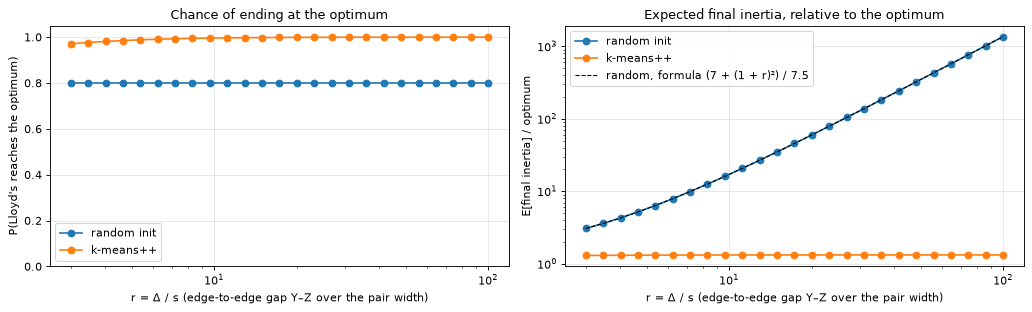

In [9]:
def compare_inits(r, s=1.0):
    """P(optimum) and E[final inertia] / optimum under random init and k-means++, exactly, for one r."""
    X, pair = three_pairs(r, s)
    runs_r = run_all_starts(X, pair)
    opt = 3 * s**2 / 2
    assert min(inr for _, inr, _ in runs_r.values()) >= opt - 1e-9   # no start beats 3s²/2: it is the optimum
    probs = kpp_start_probabilities(X, 3)
    random_reach = np.mean([np.isclose(inr, opt) for _, inr, _ in runs_r.values()])
    random_ratio = np.mean([inr for _, inr, _ in runs_r.values()]) / opt
    kpp_reach = sum(p for st, p in probs.items() if np.isclose(runs_r[st][1], opt))
    kpp_ratio = sum(p * runs_r[st][1] for st, p in probs.items()) / opt
    return random_reach, kpp_reach, random_ratio, kpp_ratio


r_grid = np.geomspace(3, 100, 25)                                    # r < 3: the pairs stop being clear clusters
table = np.array([compare_inits(rv) for rv in r_grid])
for rv in [3, 10, 100]:
    rr, kr, rq, kq = compare_inits(rv)
    print(f"r = {rv:3d}: P(optimum) random {rr:.2f}, k-means++ {kr:.5f} | "
          f"E[inertia]/optimum random {rq:8.2f}, k-means++ {kq:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(r_grid, table[:, 0], marker="o", label="random init")
axes[0].plot(r_grid, table[:, 1], marker="o", label="k-means++")
axes[0].set_xscale("log"); axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel("r = Δ / s (edge-to-edge gap Y–Z over the pair width)"); axes[0].set_ylabel("P(Lloyd's reaches the optimum)")
axes[0].set_title("Chance of ending at the optimum"); axes[0].legend()
axes[1].plot(r_grid, table[:, 2], marker="o", label="random init")
axes[1].plot(r_grid, table[:, 3], marker="o", label="k-means++")
axes[1].plot(r_grid, (7 + (1 + r_grid)**2) / 7.5, "k--", lw=1, label="random, formula (7 + (1 + r)²) / 7.5")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("r = Δ / s (edge-to-edge gap Y–Z over the pair width)"); axes[1].set_ylabel("E[final inertia] / optimum")
axes[1].set_title("Expected final inertia, relative to the optimum"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * **Left:** random init reaches the optimum with probability **0.80** at every r; k-means++ goes from **0.971** at
>   r = 3 to **0.99995** at r = 100.
> * **Right (log scales):** random init's expected inertia over the optimum grows like r² and sits on the formula
>   [7 + (1 + r)²]/7.5: **3.07** at r = 3, **17.07** at r = 10, **1361.07** at r = 100. k-means++ stays flat at about
>   **1.3** (1.301, 1.321, 1.325): the stuck ending gets worse but rarer at the same rate.

**What can be proven in general, and what can't**

* **k-means++ has a guarantee.** Arthur & Vassilvitskii (2007) proved that for *every* dataset the k-means++
  seeding alone has expected inertia at most $8(\ln k + 2)$ times the optimum (about 24.8× for k = 3); Lloyd's
  only lowers it from there. The toy's 1.3× is far inside that worst-case bound.
* **Random init has no such guarantee.** The toy is a counterexample: its expected inertia over the optimum,
  $[7 + (1 + r)^2]/7.5$, grows without limit as r grows.
* **"k-means++ needs fewer iterations" is a tendency, not a theorem.** Lloyd's can need exponentially many iterations
  in the worst case (Vattani 2011) and a polynomial number in the smoothed sense (Arthur, Manthey & Röglin 2009),
  whatever the start. In the toy the extra iterations of random init are Lloyd's repairing bad starts, and the worst
  starts converge fastest.

<a id="lab-3"></a>

## Lab 3 · Choosing k: the elbow and the silhouette

*Library twin:* [Lab 3 in `kmeans_lab.ipynb`](kmeans_lab.ipynb#lab-3) runs both rules on clear blobs, two pairs of blobs, and pure noise.

**[README §6](README.md#6-choosing-k).** For every point $i$:

* $a(i)$ = mean distance to the **other** points of its own cluster (divide by $n_\text{own} - 1$, because the point's
  zero distance to itself doesn't count);
* $b(i)$ = for every other cluster, the mean distance from $i$ to its points; take the smallest;
* $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, and $s(i) = 0$ for a point alone in its cluster.

The mean of $s(i)$ is the silhouette score. The **elbow** is found with the chord rule from library [Lab 3](kmeans_lab.ipynb#lab-3): rescale the
inertia curve to 0–1 on both axes and take the k farthest from the straight line between its two ends. Each k uses
the best of 5 runs of our k-means with k-means++ starts.

inertia per k : [20725. 10691.  5780.  1136.  1019.   916.   799.   774.]
silhouette ours   : [0.499 0.594 0.769 0.665 0.546 0.46  0.437]
silhouette sklearn: [0.499 0.594 0.769 0.665 0.546 0.46  0.437]
elbow (chord rule) k = 4, best silhouette k = 4


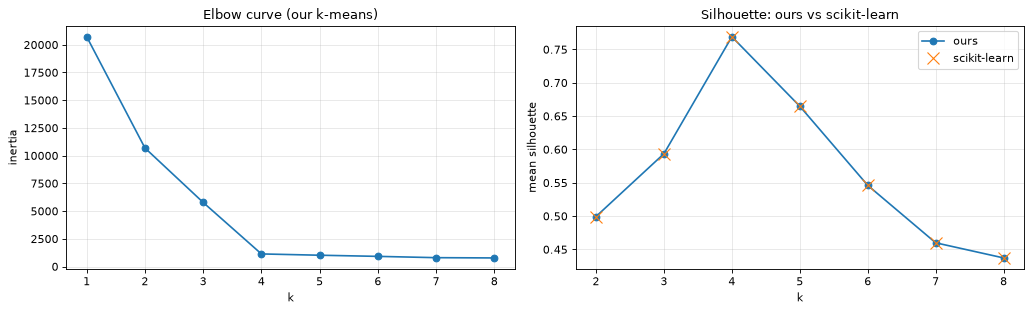

In [10]:
def silhouette_values(D, labels):
    """Silhouette s(i) = (b - a) / max(a, b) for every point, where
    a = mean distance to the other points of its own cluster, b = smallest mean distance to another cluster.
    D is the n x n point-to-point distance matrix: it depends only on the data, so it is built once and reused
    for every k (only the labels change)."""
    clusters = np.unique(labels)
    s = np.zeros(len(D))
    for i in range(len(D)):
        own = labels == labels[i]
        if own.sum() == 1:                             # a cluster of one: s(i) is defined as 0
            continue
        a = D[i, own].sum() / (own.sum() - 1)          # divide by n_own - 1: the distance to itself (0) is excluded
        b = min(D[i, labels == c].mean() for c in clusters if c != labels[i])
        s[i] = (b - a) / max(a, b)
    return s


def knee_by_chord(ks, values):
    """The k whose point lies farthest from the straight line joining the first and last points (the elbow)."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks[0]) / (ks[-1] - ks[0])                         # rescale both axes to 0..1 so the units don't matter
    v = (values - values.min()) / (values.max() - values.min())
    chord = v[0] + (v[-1] - v[0]) * x                            # height of the straight line at each k
    return int(ks[np.argmax(np.abs(chord - v))])


X_k, _ = make_blobs(400, centers=[[-5, -5], [5, -5], [-5, 5], [5, 5]], cluster_std=1.2, random_state=1)
ks = list(range(1, 9))
D_k = pairwise_distances(X_k, X_k)                     # all point-to-point distances, n x n: built once, reused for every k
inertias, sil_ours, sil_sklearn = [], [], []
for k in ks:
    rng = np.random.default_rng(SEED)
    runs = [kmeans(X_k, kmeans_plus_plus(X_k, k, rng)) for _ in range(5)]    # best of 5 k-means++ runs
    lab, cen, hist = min(runs, key=lambda run: run[2][-1])
    inertias.append(hist[-1])                         # the elbow's number: already computed inside kmeans()
    if k > 1:
        sil_ours.append(silhouette_values(D_k, lab).mean())      # the silhouette's: a new pass over D_k
        sil_sklearn.append(silhouette_score(X_k, lab))
print("inertia per k :", np.round(inertias, 0))
print("silhouette ours   :", np.round(sil_ours, 4))
print("silhouette sklearn:", np.round(sil_sklearn, 4))
print(f"elbow (chord rule) k = {knee_by_chord(ks, inertias)}, best silhouette k = {ks[1:][int(np.argmax(sil_ours))]}")
assert np.allclose(sil_ours, sil_sklearn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow curve (our k-means)")
axes[1].plot(ks[1:], sil_ours, marker="o", label="ours"); axes[1].plot(ks[1:], sil_sklearn, "x", ms=10, label="scikit-learn")
axes[1].set_xlabel("k"); axes[1].set_ylabel("mean silhouette"); axes[1].set_title("Silhouette: ours vs scikit-learn")
axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Our silhouette equals scikit-learn's at every k (**0.499, 0.594, 0.769, 0.665, …**); the `assert` checks all of
>   them.
> * Both rules pick **k = 4**, the four blobs: the inertia drops steeply until k = 4 (20725 → 1136) and slowly after.

<a id="lab-3-cost"></a>

### What each rule costs as n grows

*Library twin:* [Lab 3](kmeans_lab.ipynb#lab-3) calls `silhouette_score`; this is why it gets slow on big data.
**[README §6](README.md#6-choosing-k).**

Both rules need one k-means fit per k. What each adds on top of that fit:

* **Elbow (inertia):** every `assign` step already computes each point's distance to every centroid, to pick the
  nearest one, and returns the squared distance to it. `kmeans()` stores the inertia as `squared.sum()` of those
  numbers. The only extra work is that sum: about n additions, and no new memory.
* **Silhouette:** $a(i)$ and $b(i)$ are means of point-to-point distances, which no k-means step computes. It needs the
  n × n matrix `D`: about $n^2 \cdot d$ time and $n^2$ numbers of memory to build (once per dataset, as above), then a
  pass over all $n^2$ entries for every k.

The cell below measures these pieces for 250 to 4,000 points (4 blobs, k = 4), taking the fastest of a few repeats
of each.

     n  assign step   WCSS sum    build D  aggregate D  WCSS memory   D memory
   250     0.012 ms     0.3 µs     0.1 ms       2.6 ms       2.0 kB     0.5 MB
   500     0.019 ms     0.5 µs     0.4 ms       6.3 ms       4.0 kB     2.0 MB
  1000     0.037 ms     0.5 µs     1.1 ms      17.1 ms       8.0 kB     8.0 MB
  2000     0.066 ms     0.6 µs     5.2 ms      41.6 ms      16.0 kB    32.0 MB
  4000     0.117 ms     0.7 µs    19.8 ms     147.5 ms      32.0 kB   128.0 MB
time grows like n to the power: assign 0.8, WCSS sum 0.2, build D 2.1, aggregate D 1.6
at n = 100,000: D needs 80 GB; building it takes ~12 s and each k ~2 min with this code; the WCSS sum needs 0.8 MB


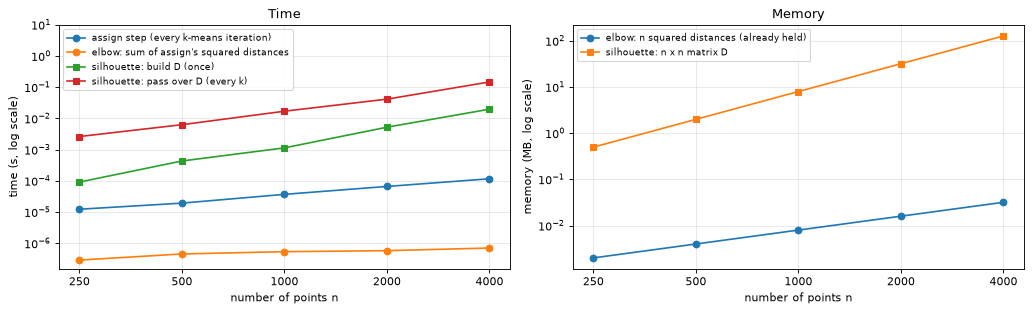

In [11]:
def fastest_time(func, repeats=5):
    """Run func() `repeats` times and return the fastest wall-clock time in seconds (the least disturbed run)."""
    times = []
    for _ in range(repeats):
        start_time = time.perf_counter()
        func()
        times.append(time.perf_counter() - start_time)
    return min(times)


sizes = [250, 500, 1000, 2000, 4000]
t_assign, t_wcss, t_build, t_aggregate, bytes_wcss, bytes_D = [], [], [], [], [], []
for n in sizes:
    X_n, _ = make_blobs(n, centers=4, cluster_std=1.2, random_state=1)       # 4 blobs, n points, 2 features
    lab_n, cen_n, _ = kmeans(X_n, kmeans_plus_plus(X_n, 4, np.random.default_rng(SEED)))   # the fit both rules need
    _, squared_n = assign(X_n, cen_n)                     # what every k-means iteration computes anyway
    D_n = pairwise_distances(X_n, X_n)                    # what only the silhouette needs
    t_assign.append(fastest_time(lambda: assign(X_n, cen_n)))           # one assign step: n x k distances
    t_wcss.append(fastest_time(lambda: squared_n.sum()))                # the elbow's extra work: one sum
    t_build.append(fastest_time(lambda: pairwise_distances(X_n, X_n), repeats=3))   # silhouette: build D (once)
    t_aggregate.append(fastest_time(lambda: silhouette_values(D_n, lab_n), repeats=3))   # silhouette: one k
    bytes_wcss.append(squared_n.nbytes)                   # n squared distances, already held by the assign step
    bytes_D.append(D_n.nbytes)                            # n x n distances
    assert np.isclose(squared_n.sum(), ((X_n - cen_n[lab_n]) ** 2).sum())   # the sum really is the inertia


def growth_exponent(values):
    """Slope of log(value) against log(n) over the three largest n: time grows roughly like n to this power."""
    return np.polyfit(np.log(sizes[-3:]), np.log(values[-3:]), 1)[0]


print(f"{'n':>6} {'assign step':>12} {'WCSS sum':>10} {'build D':>10} {'aggregate D':>12} {'WCSS memory':>12} {'D memory':>10}")
for row in zip(sizes, t_assign, t_wcss, t_build, t_aggregate, bytes_wcss, bytes_D):
    n, ta, tw, tb, tg, bw, bd = row
    print(f"{n:>6} {ta * 1e3:>9.3f} ms {tw * 1e6:>7.1f} µs {tb * 1e3:>7.1f} ms {tg * 1e3:>9.1f} ms "
          f"{bw / 1e3:>9.1f} kB {bd / 1e6:>7.1f} MB")
print("time grows like n to the power: "
      + ", ".join(f"{name} {growth_exponent(t):.1f}" for name, t in
                  [("assign", t_assign), ("WCSS sum", t_wcss), ("build D", t_build), ("aggregate D", t_aggregate)]))
scale = (100_000 / sizes[-1]) ** 2                        # n² work and memory, scaled from n = 4,000 to n = 100,000
print(f"at n = 100,000: D needs {8 * 100_000 ** 2 / 1e9:.0f} GB; building it takes ~{t_build[-1] * scale:.0f} s and "
      f"each k ~{t_aggregate[-1] * scale / 60:.0f} min with this code; the WCSS sum needs {8 * 100_000 / 1e6:.1f} MB")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(sizes, t_assign, marker="o", label="assign step (every k-means iteration)")
axes[0].loglog(sizes, t_wcss, marker="o", label="elbow: sum of assign's squared distances")
axes[0].loglog(sizes, t_build, marker="s", label="silhouette: build D (once)")
axes[0].loglog(sizes, t_aggregate, marker="s", label="silhouette: pass over D (every k)")
axes[0].set_xlabel("number of points n"); axes[0].set_ylabel("time (s, log scale)")
axes[0].set_title("Time"); axes[0].legend(fontsize=8)
axes[1].loglog(sizes, np.array(bytes_wcss) / 1e6, marker="o", label="elbow: n squared distances (already held)")
axes[1].loglog(sizes, np.array(bytes_D) / 1e6, marker="s", label="silhouette: n x n matrix D")
axes[1].set_xlabel("number of points n"); axes[1].set_ylabel("memory (MB, log scale)")
axes[1].set_title("Memory"); axes[1].legend(fontsize=8)
axes[0].set_ylim(top=10)                                  # headroom above the curves for the legend
for ax in axes:
    ax.set_xticks(sizes, [str(n) for n in sizes]); ax.minorticks_off()   # tick exactly at the measured n
plt.tight_layout(); plt.show()

> **How to read this**
> * **Time, at n = 4,000:** the elbow's extra work is one sum, **0.7 µs**. The silhouette needs **19.8 ms** to build
>   `D` and then **147.5 ms for every k**: about 200,000 times the sum. One `assign` step, which every k-means
>   iteration runs anyway, takes **0.117 ms**.
> * **Growth:** building `D` grows like **n^2.1**: double n, four times the time. The pass over `D` shows **1.6**
>   here, because our per-point Python loop adds a cost proportional to n that still matters at these sizes; from
>   2,000 to 4,000 points it already grows ×3.5 (41.6 → 147.5 ms), approaching ×4. The sum (**0.2**) is so fast that
>   fixed call overhead dominates it.
> * **Memory:** the elbow uses the **32 kB** of squared distances the assign step already holds; `D` takes
>   **128 MB**, four times more for every doubling of n.
> * **At 100,000 points:** `D` alone needs **80 GB**, more than most laptops have; this code would take ~12 s to build
>   it and ~2 min per k. scikit-learn's `silhouette_score` walks `D` in chunks, so memory stays bounded, but the time
>   is still n² per k; on big data pass `sample_size` (library [Lab 3](kmeans_lab.ipynb#lab-3)).
> * Your times will differ; the growth rates and the memory numbers won't.

<a id="lab-4b"></a>

## Lab 4b · Mini-batch k-means

*Library twin:* [Lab 4b in `kmeans_lab.ipynb`](kmeans_lab.ipynb#lab-4b) times scikit-learn's `MiniBatchKMeans` on up to
3,000,000 points and streams data through `partial_fit`.

**[README §8](README.md#8-cost-and-variants).** Lloyd's algorithm (Lab 1) looks at all n points in every iteration.
Mini-batch k-means (Sculley, 2010) looks at only a small random batch per step:

1. Draw `batch_size` random points.
2. **Assign** each to its nearest centroid (Lab 1's `assign`, on the batch only).
3. **Move** each centroid part of the way towards its batch points. Each centroid keeps a count $c_k$ of the points it
   has absorbed so far; with the $m$ new points $x_1, \dots, x_m$ of this batch,

   $$c_k \leftarrow c_k + m, \qquad \mu_k \leftarrow \mu_k + \frac{\sum_{i=1}^{m} x_i - m\,\mu_k}{c_k}$$

   so $\mu_k$ is always the **running mean** of every point ever assigned to it, and its moves shrink as $c_k$ grows.

The check: same data (200,000 points, 8 blobs, 10 features), same k-means++ start for our mini-batch, our Lloyd
(Lab 1) and scikit-learn's `MiniBatchKMeans`. The two mini-batch versions draw different batches, so they agree
closely but not exactly.

Lloyd (ours)            : inertia 11,142,284 after 294 iterations = 58,800,000 points looked at
mini-batch (ours)       : inertia 11,145,454 (0.028% above Lloyd) after 300 steps = 307,200 points looked at
MiniBatchKMeans (sklearn): inertia 11,145,463 (0.029% above Lloyd)
Lloyd was already as good as our mini-batch after 7 iterations (1,400,000 points); the other 287 iterations polish the last digits
ARI, our mini-batch vs our Lloyd: 0.9690; vs sklearn MiniBatchKMeans: 0.9830


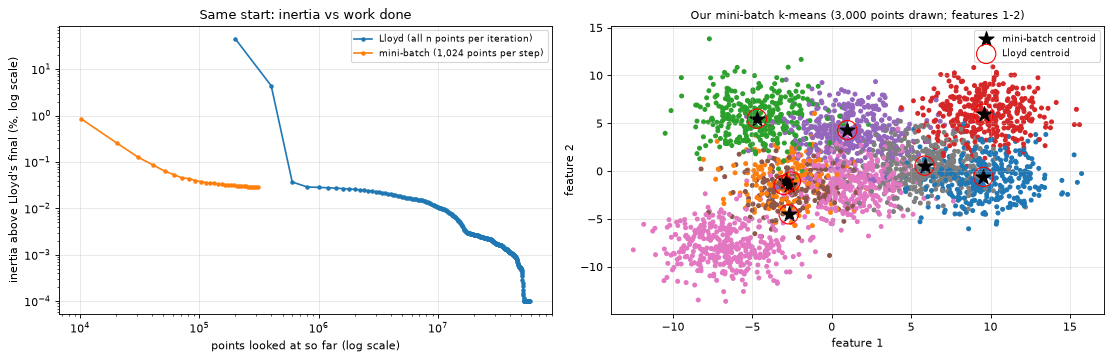

In [12]:
def minibatch_kmeans(X, initial_centroids, batch_size, n_steps, rng, step="count", track_every=10):
    """Mini-batch k-means (Sculley, 2010). Each step draws `batch_size` random points, assigns them to their nearest
    centroid, and moves each centroid part of the way towards its batch points.

    step="count": a centroid's step size is 1 / (points it has absorbed so far), so every centroid is the running mean
    of all points ever assigned to it, and its moves shrink as it settles. step=<number>: a fixed step size instead
    (the hurdle below). Returns (centroids, [(points seen, inertia on all of X)] every `track_every` steps)."""
    centroids = np.asarray(initial_centroids, dtype=float).copy()
    counts = np.zeros(len(centroids))                                     # points each centroid has absorbed so far
    history = [(0, assign(X, centroids)[1].sum())]
    for step_number in range(1, n_steps + 1):
        batch = X[rng.integers(len(X), size=batch_size)]                  # a random batch: the only points this step sees
        labels, _ = assign(batch, centroids)                              # Lab 1's assign, on the batch only
        for k in np.unique(labels):
            members = batch[labels == k]
            if step == "count":
                counts[k] += len(members)
                centroids[k] += (members.sum(axis=0) - len(members) * centroids[k]) / counts[k]   # update the running mean
            else:
                centroids[k] += step * (members.mean(axis=0) - centroids[k])                     # fixed fraction of the way
        if step_number % track_every == 0:
            history.append((step_number * batch_size, assign(X, centroids)[1].sum()))         # costs a full pass: only to plot
    return centroids, history


# 200,000 points, 8 blobs, 10 features; the same k-means++ start for every method
X_mb, _ = make_blobs(200_000, centers=8, n_features=10, cluster_std=2.0, random_state=SEED)
start_mb = kmeans_plus_plus(X_mb, 8, np.random.default_rng(SEED))
batch_size, n_steps = 1024, 300                                           # <- try changing this

labels_lloyd, centroids_lloyd, history_lloyd = kmeans(X_mb, start_mb)    # Lab 1: every iteration looks at all n points
centroids_mini, history_mini = minibatch_kmeans(X_mb, start_mb, batch_size, n_steps, np.random.default_rng(SEED))
labels_mini, squared_mini = assign(X_mb, centroids_mini)
reference = MiniBatchKMeans(8, init=start_mb, n_init=1, batch_size=batch_size, random_state=SEED).fit(X_mb)

inertia_lloyd = history_lloyd[-1]
print(f"Lloyd (ours)            : inertia {inertia_lloyd:,.0f} after {len(history_lloyd)} iterations "
      f"= {len(history_lloyd) * len(X_mb):,} points looked at")
print(f"mini-batch (ours)       : inertia {squared_mini.sum():,.0f} ({(squared_mini.sum() / inertia_lloyd - 1) * 100:.3f}% above Lloyd) "
      f"after {n_steps} steps = {n_steps * batch_size:,} points looked at")
print(f"MiniBatchKMeans (sklearn): inertia {-reference.score(X_mb):,.0f} ({(-reference.score(X_mb) / inertia_lloyd - 1) * 100:.3f}% above Lloyd)")
caught_up = next(i for i, inertia in enumerate(history_lloyd, start=1) if inertia <= squared_mini.sum())
print(f"Lloyd was already as good as our mini-batch after {caught_up} iterations "
      f"({caught_up * len(X_mb):,} points); the other {len(history_lloyd) - caught_up} iterations polish the last digits")
print(f"ARI, our mini-batch vs our Lloyd: {adjusted_rand_score(labels_lloyd, labels_mini):.4f}; "
      f"vs sklearn MiniBatchKMeans: {adjusted_rand_score(reference.predict(X_mb), labels_mini):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
def above_lloyd(inertias):
    """Percent above Lloyd's final inertia, floored at 0.0001 % so that a log scale can show 'equal'."""
    return np.maximum((np.asarray(inertias) / inertia_lloyd - 1) * 100, 1e-4)


seen_lloyd = np.arange(1, len(history_lloyd)) * len(X_mb)                 # after iteration i, Lloyd has looked at i x n points
seen_mini, inertia_mini = zip(*history_mini[1:])                         # skip the shared start (0 points looked at)
axes[0].plot(seen_lloyd, above_lloyd(history_lloyd[1:]), marker="o", ms=3, label="Lloyd (all n points per iteration)")
axes[0].plot(seen_mini, above_lloyd(inertia_mini), marker=".", label=f"mini-batch ({batch_size:,} points per step)")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("points looked at so far (log scale)"); axes[0].set_ylabel("inertia above Lloyd's final (%, log scale)")
axes[0].set_title("Same start: inertia vs work done"); axes[0].legend(fontsize=8)
plot_clusters(axes[1], X_mb[:3000, :2], labels_mini[:3000], "Our mini-batch k-means (3,000 points drawn; features 1-2)")
axes[1].scatter(*centroids_mini[:, :2].T, c="black", marker="*", s=200, label="mini-batch centroid")
axes[1].scatter(*centroids_lloyd[:, :2].T, facecolors="none", edgecolors="red", s=300, label="Lloyd centroid")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


> **How to read this**
> * **Nearly the same answer for a fraction of the work.** Our mini-batch ends **0.028%** above Lloyd's inertia after
>   looking at **307,200** points (300 batches of 1,024). Lloyd needed **7** full iterations (**1,400,000** points,
>   about 4.6× more) to be as good, and **294** iterations (58,800,000 points) to stop completely.
> * **The trade-off (left):** mini-batch falls fast, then flattens at about 0.03%: every batch is a noisy sample, so
>   the centroids hover near the answer. Lloyd keeps polishing down to its exact local minimum.
> * **Matches scikit-learn:** `MiniBatchKMeans` from the same start ends **0.029%** above Lloyd (ours 0.028%), and the
>   labels agree at ARI **0.983**: the two draw different random batches, so they are close, not identical.
> * **ARI 0.969 against Lloyd**, although the inertia is within 0.03%: the blobs overlap, and points on a border
>   switch cluster when a centroid shifts slightly. The centroids themselves sit on Lloyd's (right).

<a id="lab-4b-step"></a>

> **Implementation hurdle — the step size.** The obvious update, "move each centroid a fixed fraction of the way
> towards its batch mean", never lets a centroid settle: every new batch pulls it somewhere slightly different, so it
> keeps jittering around the right spot. The `1 / count` step above shrinks with every point absorbed, so the moves
> die down. Below: the same start and the same random batches, with the running-mean step and two fixed steps.

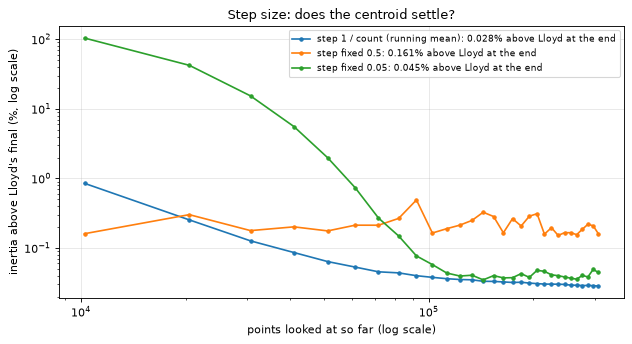

step count: final inertia 0.028% above Lloyd
step   0.5: final inertia 0.161% above Lloyd
step  0.05: final inertia 0.045% above Lloyd


In [13]:
# The same start and the same random batches, three step sizes
final_excess = {}
fig, ax = plt.subplots(figsize=(8, 4.4))
for step in ["count", 0.5, 0.05]:                                          # <- try changing this
    centroids_step, history_step = minibatch_kmeans(X_mb, start_mb, batch_size, n_steps, np.random.default_rng(SEED), step=step)
    final_excess[step] = (assign(X_mb, centroids_step)[1].sum() / inertia_lloyd - 1) * 100
    label = "1 / count (running mean)" if step == "count" else f"fixed {step}"
    seen, inertias = zip(*history_step[1:])                                 # skip the shared start
    ax.plot(seen, above_lloyd(inertias), marker=".", label=f"step {label}: {final_excess[step]:.3f}% above Lloyd at the end")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("points looked at so far (log scale)"); ax.set_ylabel("inertia above Lloyd's final (%, log scale)")
ax.set_title("Step size: does the centroid settle?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for step, excess in final_excess.items():
    print(f"step {step!s:>5}: final inertia {excess:.3f}% above Lloyd")


> **How to read this**
> * **Running mean (step 1 / count): 0.028%** above Lloyd, and still falling at the end.
> * **Fixed step 0.5: 0.161%**, and flat from the start: every batch pulls each centroid half-way to that batch's mean,
>   so it zig-zags around the answer forever.
> * **Fixed step 0.05: 0.045%**: smaller jumps, but a slow start (about 100% above Lloyd after the first batch, since
>   each step covers only 5% of the way), and it still jitters at the end.
> * A fixed step trades speed against jitter; the shrinking step gets both. scikit-learn's `MiniBatchKMeans` also
>   scales each centroid's step by the number of points it has absorbed.

---

<a id="summary"></a>

## Summary

| Lab | Our implementation | Matches the library? | Hurdle shown |
|---|---|---|---|
| [1](#lab-1) | k-means: `assign`, `update`, `kmeans` | ✔ identical labels, inertia and iteration count | empty clusters (NaN); n × k × d memory blow-up |
| [2](#lab-2) | k-means++ | ✔ same idea; sklearn's greedy variant is a bit better (29 % vs 50 % best runs) | — |
| [2 · toy](#toy) | exact toy, 3 pairs: all random starts and exact k-means++ probabilities | ✔ all 20 starts match `KMeans`; Monte Carlo agrees | random init stuck 20 % of the time, at (2/3)[1 + (1 + r)²] × the optimum |
| [3](#lab-3) | silhouette, chord-rule elbow | ✔ silhouette equal at every k | [cost](#lab-3-cost): the silhouette's n × n matrix vs the elbow's free sum |
| 4 | not rebuilt: the failures come from the objective, not the code | — | — |
| [4b](#lab-4b) | mini-batch k-means: running-mean update on random batches | ✔ 0.028% above Lloyd after 307,200 points (Lloyd needs 1,400,000); `MiniBatchKMeans` 0.029%, ARI 0.983 | [step size](#lab-4b-step): a fixed step never settles |